# Module 05: Backpropagation, Computational Graphs, and Automatic Differentiation

Backpropagation is how neural networks calculate gradients efficiently. This module explains the computation graph, local derivatives, upstream gradients, chain rule, vectorized layer gradients, vanishing/exploding gradients, gradient checking, and automatic differentiation.


## Module outline

* **Step 1: Computational Graph Foundations**
  * Node, edge, operation, input variable, parameter, intermediate value, output, loss node, cached value.
* **Step 2: Local Gradients**
  * Add gradient, multiply gradient, square gradient, sigmoid gradient, tanh gradient, ReLU gradient.
* **Step 3: Upstream and Downstream Gradients**
  * Upstream gradient, local gradient, downstream gradient, gradient flow, multiplication through paths.
* **Step 4: Chain Rule for Networks**
  * Nested function, chain rule, path contribution, branching graph, gradient accumulation.
* **Step 5: Manual Backpropagation for One Neuron**
  * Forward values, MSE loss, sigmoid derivative, weight gradient, bias gradient, input gradient.
* **Step 6: Vectorized Backpropagation for a Layer**
  * Batch gradients, $dW$, $db$, $dX$, hidden-layer gradient, shape verification.
* **Step 7: Activation and Loss Derivatives**
  * Sigmoid derivative, tanh derivative, ReLU derivative, MSE derivative, BCE derivative, softmax-cross-entropy gradient.
* **Step 8: Vanishing and Exploding Gradients**
  * Repeated multiplication, saturation, exploding norms, clipping preview, residual connection preview.
* **Step 9: Gradient Checking**
  * Finite difference, numerical gradient, analytical gradient, epsilon, tolerance, debugging.
* **Step 10: Automatic Differentiation**
  * Forward recording, backward pass, dynamic graph, static graph, autograd, framework purpose.
* **Step 11: Backpropagation Mistakes**
  * Missing cache, wrong shape, no batch average, early update, not clearing gradients, detached graph.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error, mean_squared_error

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10
rng = np.random.default_rng(42)


## Step 1: Computational Graph Foundations

A computational graph breaks one large formula into small operations. Backpropagation walks through this graph backward from the loss to the parameters.


### 1.1 Node

**Definition:** A value or operation in the computation graph.

**Where it is used:** Every autograd framework.

**Why it matters:** It gives backpropagation a place to apply local derivatives.

**Simple example:** A multiply operation is a node.

**Common mistake:** Thinking only parameters are nodes.


### 1.2 Edge

**Definition:** A connection showing one value feeding another operation.

**Where it is used:** Graph execution and gradient flow.

**Why it matters:** It defines paths from parameters to loss.

**Simple example:** x and w feed into multiply.

**Common mistake:** Ignoring branches where one value affects loss through multiple paths.


### 1.3 Parameter

**Definition:** A trainable value updated by the optimizer.

**Where it is used:** Weights and biases.

**Why it matters:** Gradients are needed mainly for parameters.

**Simple example:** w and b in xw+b are parameters.

**Common mistake:** Updating intermediate activations as if they are parameters.


### 1.4 Intermediate value

**Definition:** A computed value between input and loss.

**Where it is used:** Forward cache for backward pass.

**Why it matters:** Many derivatives need it.

**Simple example:** Sigmoid backward uses sigmoid output.

**Common mistake:** Recomputing incorrectly or losing it.


### 1.5 Loss node

**Definition:** Final scalar objective used to start backpropagation.

**Where it is used:** Training loops.

**Why it matters:** Gradients flow backward from this scalar.

**Simple example:** MSE loss after prediction.

**Common mistake:** Trying to backpropagate from a non-scalar without specifying gradient.


In [2]:
x=2.0; w=-1.5; b=.5; y=1.0
z=x*w+b
yhat=1/(1+np.exp(-z))
L=(yhat-y)**2
print('z:',z,'yhat:',yhat,'loss:',L)


z: -2.5 yhat: 0.07585818002124355 loss: 0.8540381034336483


## Step 2: Local Gradients

A local gradient is the derivative of one operation with respect to its direct input.


### 2.1 Add gradient

**Definition:** For z=x+y, derivative with respect to each input is 1.

**Where it is used:** Bias addition and residual connections.

**Why it matters:** Addition passes gradient unchanged to each input.

**Simple example:** d(x+y)/dx=1.

**Common mistake:** Forgetting gradients split to both branches.


### 2.2 Multiply gradient

**Definition:** For z=xy, derivative wrt x is y and wrt y is x.

**Where it is used:** Weighted sums and gates.

**Why it matters:** Each input scales the other's gradient.

**Simple example:** If z=3x, dz/dx=3.

**Common mistake:** Forgetting multiplication can amplify gradients.


### 2.3 Square gradient

**Definition:** For z=x², derivative is 2x.

**Where it is used:** MSE loss and regularization.

**Why it matters:** Large values produce larger gradients.

**Simple example:** At x=4, gradient is 8.

**Common mistake:** Ignoring sign: at x=-4, gradient is -8.


### 2.4 Sigmoid gradient

**Definition:** Derivative is sigmoid(z)(1-sigmoid(z)).

**Where it is used:** Binary outputs and old hidden layers.

**Why it matters:** It becomes tiny when sigmoid saturates.

**Simple example:** At output .5, derivative is .25.

**Common mistake:** Using z instead of sigmoid output in this formula.


### 2.5 ReLU gradient

**Definition:** Derivative is 1 for positive input and 0 for negative input.

**Where it is used:** Hidden layers.

**Why it matters:** It keeps positive gradients simple but blocks negative units.

**Simple example:** At z=3 gradient is 1; at z=-2 gradient is 0.

**Common mistake:** Forgetting the zero-gradient dead ReLU issue.


In [3]:
x,yv=3.0,4.0
print('add dz/dx,dz/dy:',1,1)
print('multiply dz/dx,dz/dy:',yv,x)
print('square dz/dx at x=3:',2*x)
for v in [-2,0,3]:
    print('ReLU gradient at',v,'=',1 if v>0 else 0)


add dz/dx,dz/dy: 1 1
multiply dz/dx,dz/dy: 4.0 3.0
square dz/dx at x=3: 6.0
ReLU gradient at -2 = 0
ReLU gradient at 0 = 0
ReLU gradient at 3 = 1


## Step 3: Upstream and Downstream Gradients

A node receives an upstream gradient from later operations. It multiplies that by the local gradient to produce downstream gradients for earlier values.


### 3.1 Upstream gradient

**Definition:** Gradient arriving from the output side of the graph.

**Where it is used:** Every backward operation.

**Why it matters:** It tells a node how much the final loss depends on its output.

**Simple example:** If dL/dz=12, 12 is upstream for z.

**Common mistake:** Confusing upstream with local derivative.


### 3.2 Local gradient

**Definition:** Derivative of the current operation itself.

**Where it is used:** Backward rule for each operation.

**Why it matters:** It describes only this operation's sensitivity.

**Simple example:** For z=3x, local dz/dx=3.

**Common mistake:** Using global loss derivative as local gradient.


### 3.3 Downstream gradient

**Definition:** Gradient sent to earlier nodes.

**Where it is used:** Backpropagation.

**Why it matters:** It combines upstream effect and local effect.

**Simple example:** dL/dx=(dL/dz)(dz/dx).

**Common mistake:** Dropping multiplication in the chain.


In [4]:
x=2.0; z=3*x; L=z**2
up=2*z; local=3; down=up*local
print('z',z,'loss',L,'upstream dL/dz',up,'local dz/dx',local,'downstream dL/dx',down)


z 6.0 loss 36.0 upstream dL/dz 12.0 local dz/dx 3 downstream dL/dx 36.0


## Step 4: Chain Rule for Networks

The chain rule connects derivatives through nested functions. If a value affects loss through several paths, the path gradients are added.


### 4.1 Nested function

**Definition:** A function inside another function.

**Where it is used:** Layers stacked in networks.

**Why it matters:** Each layer output becomes next layer input.

**Simple example:** L=f(g(h(x))).

**Common mistake:** Trying to differentiate only the last function.


### 4.2 Path contribution

**Definition:** Gradient contribution along one route in the graph.

**Where it is used:** Branching graphs and residual connections.

**Why it matters:** Each route has its own effect on loss.

**Simple example:** x affects L through x² and 3x.

**Common mistake:** Forgetting to add all path contributions.


### 4.3 Gradient accumulation

**Definition:** Adding gradients from multiple paths or batches.

**Where it is used:** Autograd and parameter updates.

**Why it matters:** One parameter can influence loss many times.

**Simple example:** Shared weight used twice gets two gradient contributions.

**Common mistake:** Overwriting a gradient instead of accumulating it.


In [5]:
x=2.0
grad_x2=2*x
grad_3x=3
print('gradient from x^2 path:',grad_x2)
print('gradient from 3x path:',grad_3x)
print('total gradient:',grad_x2+grad_3x)


gradient from x^2 path: 4.0
gradient from 3x path: 3
total gradient: 7.0


## Step 5: Manual Backpropagation for One Neuron

For $z=xw+b$, $\hat y=\sigma(z)$, and $L=(\hat y-y)^2$, each parameter gradient is found by multiplying derivatives along the path from loss back to that parameter.


### 5.1 Weight gradient

**Definition:** How loss changes when a weight changes.

**Where it is used:** Optimizer weight updates.

**Why it matters:** It tells whether to increase or decrease the weight.

**Simple example:** dL/dw = dL/dyhat * dyhat/dz * dz/dw.

**Common mistake:** Forgetting dz/dw equals input x.


### 5.2 Bias gradient

**Definition:** How loss changes when bias changes.

**Where it is used:** Optimizer bias updates.

**Why it matters:** Bias shifts the neuron score.

**Simple example:** dz/db=1, so dL/db passes the earlier chain through.

**Common mistake:** Summing bias gradient over wrong axis.


### 5.3 Input gradient

**Definition:** How loss changes with respect to input.

**Where it is used:** Earlier layers in backpropagation.

**Why it matters:** Hidden layers need this to send gradient backward.

**Simple example:** dL/dx includes weight w.

**Common mistake:** Ignoring dX in hidden layers.


In [6]:
x=2.0; w=-1.5; b=.5; y=1.0
z=x*w+b; yhat=1/(1+np.exp(-z)); L=(yhat-y)**2
dL_dyhat=2*(yhat-y); dyhat_dz=yhat*(1-yhat)
dL_dw=dL_dyhat*dyhat_dz*x
dL_db=dL_dyhat*dyhat_dz
dL_dx=dL_dyhat*dyhat_dz*w
print('forward:',{'z':z,'yhat':yhat,'loss':L})
print('gradients:',{'dL/dw':dL_dw,'dL/db':dL_db,'dL/dx':dL_dx})


forward: {'z': -2.5, 'yhat': np.float64(0.07585818002124355), 'loss': np.float64(0.8540381034336483)}
gradients: {'dL/dw': np.float64(-0.25914310478108443), 'dL/db': np.float64(-0.12957155239054222), 'dL/dx': np.float64(0.19435732858581334)}


## Step 6: Vectorized Backpropagation for a Layer

For $Z=XW+b$ and incoming gradient $dZ$: $dW=X^TdZ$, $db=sum(dZ)$, and $dX=dZW^T$.


### 6.1 Batch gradient

**Definition:** Gradient calculated for several examples at once.

**Where it is used:** Mini-batch training.

**Why it matters:** It makes training efficient and stable.

**Simple example:** A batch of 32 creates dZ with 32 rows.

**Common mistake:** Forgetting to average or sum consistently.


### 6.2 $dW$

**Definition:** Gradient with same shape as W.

**Where it is used:** Weight update for dense layers.

**Why it matters:** It combines input values and output gradients.

**Simple example:** X.T @ dZ.

**Common mistake:** Using X @ dZ and getting wrong shape.


### 6.3 $db$

**Definition:** Gradient with same shape as bias.

**Where it is used:** Bias update.

**Why it matters:** Bias receives one contribution from each row.

**Simple example:** sum dZ over batch axis.

**Common mistake:** Summing over output axis by mistake.


### 6.4 $dX$

**Definition:** Gradient sent to previous layer.

**Where it is used:** Hidden-layer backpropagation.

**Why it matters:** Earlier layers need it to continue chain rule.

**Simple example:** dZ @ W.T.

**Common mistake:** Stopping backprop at a hidden layer.


In [7]:
X=rng.normal(size=(4,3)); W=rng.normal(size=(3,2)); b=np.zeros((1,2))
Z=X@W+b; dZ=rng.normal(size=Z.shape)
dW=X.T@dZ; db=dZ.sum(axis=0,keepdims=True); dX=dZ@W.T
print('X',X.shape,'W',W.shape,'Z',Z.shape,'dW',dW.shape,'db',db.shape,'dX',dX.shape)


X (4, 3) W (3, 2) Z (4, 2) dW (3, 2) db (1, 2) dX (4, 3)


## Step 7: Activation and Loss Derivatives

These derivatives appear repeatedly in network training.


### 7.1 MSE derivative

**Definition:** Derivative wrt prediction is 2(yhat-y)/n.

**Where it is used:** Regression and simple demos.

**Why it matters:** It points predictions toward targets.

**Simple example:** If prediction is too high, gradient is positive.

**Common mistake:** Forgetting division by batch size when averaging loss.


### 7.2 BCE derivative

**Definition:** Derivative of binary cross-entropy wrt probability.

**Where it is used:** Binary classification.

**Why it matters:** It strongly penalizes confident wrong predictions.

**Simple example:** y=1 and p close to 0 gives huge negative derivative.

**Common mistake:** Not clipping probabilities in manual code.


### 7.3 Softmax-cross-entropy gradient

**Definition:** Gradient wrt logits is p-y.

**Where it is used:** Multiclass classification.

**Why it matters:** It simplifies a complex derivative into prediction minus target.

**Simple example:** If correct class prob is .2, its logit gradient is -.8.

**Common mistake:** Applying softmax twice before cross-entropy.


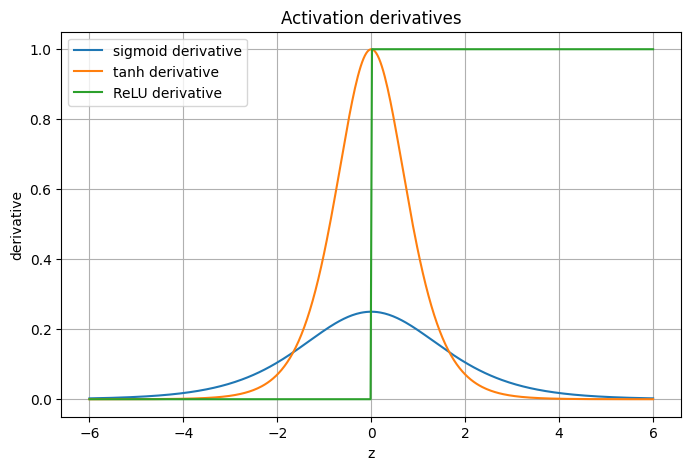

In [8]:
z=np.linspace(-6,6,400)
sig=1/(1+np.exp(-z))
plt.plot(z,sig*(1-sig),label='sigmoid derivative')
plt.plot(z,1-np.tanh(z)**2,label='tanh derivative')
plt.plot(z,(z>0).astype(float),label='ReLU derivative')
plt.title('Activation derivatives'); plt.xlabel('z'); plt.ylabel('derivative'); plt.legend();


## Step 8: Vanishing and Exploding Gradients

Gradients are repeatedly multiplied through layers. Repeated values below 1 shrink; repeated values above 1 grow.


### 8.1 Vanishing gradient

**Definition:** Gradient becomes too small to update early layers.

**Where it is used:** Deep sigmoid/tanh networks and RNNs.

**Why it matters:** Learning becomes slow or stops in early layers.

**Simple example:** 0.7 multiplied 50 times is tiny.

**Common mistake:** Thinking loss is stuck only because learning rate is low.


### 8.2 Exploding gradient

**Definition:** Gradient becomes extremely large.

**Where it is used:** Deep or recurrent networks.

**Why it matters:** Updates can become unstable or NaN.

**Simple example:** 1.2 multiplied 50 times is large.

**Common mistake:** Ignoring gradient norm spikes.


### 8.3 Gradient clipping

**Definition:** Limiting gradient norm or value.

**Where it is used:** RNNs and unstable training.

**Why it matters:** It prevents huge updates.

**Simple example:** Clip norm to 1.0.

**Common mistake:** Using clipping to hide a bad loss or data bug.


### 8.4 Residual connection preview

**Definition:** Adds shortcut paths for gradients.

**Where it is used:** ResNets and transformers.

**Why it matters:** It helps gradients flow through deep models.

**Simple example:** Layer output = F(x)+x.

**Common mistake:** Assuming residuals remove all optimization issues.


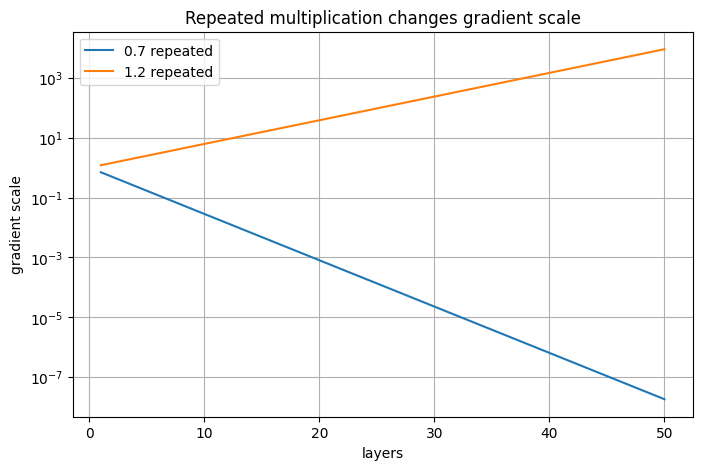

In [9]:
depth=np.arange(1,51)
plt.semilogy(depth,.7**depth,label='0.7 repeated')
plt.semilogy(depth,1.2**depth,label='1.2 repeated')
plt.title('Repeated multiplication changes gradient scale'); plt.xlabel('layers'); plt.ylabel('gradient scale'); plt.legend();


## Step 9: Gradient Checking

Gradient checking compares backpropagation gradients with finite-difference numerical gradients.


### 9.1 Finite difference

**Definition:** Estimate derivative by checking small parameter changes.

**Where it is used:** Debugging manual backprop.

**Why it matters:** It provides an independent gradient estimate.

**Simple example:** (L(w+eps)-L(w-eps))/(2eps).

**Common mistake:** Using epsilon too large or too tiny.


### 9.2 Analytical gradient

**Definition:** Gradient from calculus/backpropagation.

**Where it is used:** Training and optimizer updates.

**Why it matters:** It is efficient for many parameters.

**Simple example:** dL/dw from chain rule.

**Common mistake:** Trusting it without checking custom code.


### 9.3 Tolerance

**Definition:** Allowed difference between numerical and analytical gradients.

**Where it is used:** Gradient-check tests.

**Why it matters:** Tiny floating-point differences are normal.

**Simple example:** Difference 1e-8 is usually fine.

**Common mistake:** Expecting exact equality.


In [10]:
def loss_w(w):
    x=2.0; b=.5; y=1.0
    yh=1/(1+np.exp(-(x*w+b)))
    return (yh-y)**2
w=-1.5; eps=1e-5
num=(loss_w(w+eps)-loss_w(w-eps))/(2*eps)
x=2.0; b=.5; y=1.0; yh=1/(1+np.exp(-(x*w+b)))
ana=2*(yh-y)*yh*(1-yh)*x
print('numerical:',num,'analytical:',ana,'difference:',abs(num-ana))


numerical: -0.25914310479158154 analytical: -0.25914310478108443 difference: 1.0497103186679624e-11


## Step 10: Automatic Differentiation

Automatic differentiation records operations during the forward pass and applies local derivative rules in reverse during the backward pass.


### 10.1 Autograd

**Definition:** Automatic gradient calculation.

**Where it is used:** PyTorch, TensorFlow, JAX.

**Why it matters:** It avoids manually coding gradients for huge models.

**Simple example:** Call backward on a scalar loss.

**Common mistake:** Believing autograd chooses the correct loss or model for you.


### 10.2 Dynamic graph

**Definition:** Graph built as code runs.

**Where it is used:** PyTorch-style eager execution.

**Why it matters:** It is flexible for Python control flow.

**Simple example:** Different branches can run for different inputs.

**Common mistake:** Expecting it to behave like a fixed compiled graph.


### 10.3 Static graph

**Definition:** Graph defined/compiled before execution.

**Where it is used:** TensorFlow graph mode and compiled systems.

**Why it matters:** It can optimize execution.

**Simple example:** Compile once, run many times.

**Common mistake:** Harder debugging if graph construction is wrong.


### 10.4 Detached graph

**Definition:** A value removed from gradient tracking.

**Where it is used:** Inference, logging, frozen features.

**Why it matters:** Useful when gradients should stop.

**Simple example:** Detach a tensor before converting to NumPy.

**Common mistake:** Accidentally detaching and stopping learning.


In [11]:
# Mini autograd-style backward for L=(x*w+b)^2
x,w,b=2.0,-1.5,.5
mul=x*w; add=mul+b; loss=add**2
dadd=2*add
dw=dadd*x; db=dadd; dx=dadd*w
print('loss:',loss,'gradients:',{'dw':dw,'db':db,'dx':dx})


loss: 6.25 gradients: {'dw': -10.0, 'db': -5.0, 'dx': 7.5}


## Deep Dive A: Backpropagation as Responsibility Assignment

Backpropagation answers one question:

**Which earlier value was responsible for the final loss, and by how much?**

It does not try random changes blindly. It uses calculus to assign responsibility to each parameter. A large gradient means a small parameter change can strongly change the loss. A small gradient means the parameter currently has little effect on the loss or the signal is blocked.


## Deep Dive B: Full One-Neuron Backpropagation Table

For:

$$z=xw+b$$
$$a=\sigma(z)$$
$$L=(a-y)^2$$

The backward path is:

| Quantity | Formula | Meaning |
|---|---|---|
| $dL/da$ | $2(a-y)$ | how loss changes if prediction changes |
| $da/dz$ | $a(1-a)$ | how sigmoid output changes if score changes |
| $dz/dw$ | $x$ | how score changes if weight changes |
| $dz/db$ | $1$ | how score changes if bias changes |
| $dz/dx$ | $w$ | how score changes if input changes |
| $dL/dw$ | $(dL/da)(da/dz)(dz/dw)$ | weight responsibility |
| $dL/db$ | $(dL/da)(da/dz)(dz/db)$ | bias responsibility |
| $dL/dx$ | $(dL/da)(da/dz)(dz/dx)$ | signal sent to earlier layer |


In [12]:
x=2.0; w=-1.5; b=.5; y=1.0
z=x*w+b
a=1/(1+np.exp(-z))
L=(a-y)**2
rows = []
rows.append(('z', z, 'x*w+b'))
rows.append(('a', a, 'sigmoid(z)'))
rows.append(('L', L, '(a-y)^2'))
dL_da=2*(a-y)
da_dz=a*(1-a)
rows.append(('dL/da', dL_da, '2(a-y)'))
rows.append(('da/dz', da_dz, 'a(1-a)'))
rows.append(('dL/dw', dL_da*da_dz*x, '(dL/da)(da/dz)x'))
rows.append(('dL/db', dL_da*da_dz, '(dL/da)(da/dz)'))
rows.append(('dL/dx', dL_da*da_dz*w, '(dL/da)(da/dz)w'))
display(pd.DataFrame(rows, columns=['quantity','value','formula']))


,quantity,value,formula
0,z,-2.500000,x*w+b
1,a,0.075858,sigmoid(z)
2,L,0.854038,(a-y)^2
3,dL/da,-1.848284,2(a-y)
4,da/dz,0.070104,a(1-a)
5,dL/dw,-0.259143,(dL/da)(da/dz)x
6,dL/db,-0.129572,(dL/da)(da/dz)
7,dL/dx,0.194357,(dL/da)(da/dz)w


**Output meaning:** every gradient is built from small local pieces. This is the same logic used in large networks, only repeated many more times.


## Deep Dive C: Two-Layer Backpropagation Shape Walkthrough

For a two-layer MLP:

$$Z_1=XW_1+b_1$$
$$A_1=ReLU(Z_1)$$
$$Z_2=A_1W_2+b_2$$
$$L=loss(Z_2,y)$$

Backward pass:

* $dZ_2$ starts from the output loss.
* $dW_2=A_1^TdZ_2$
* $db_2=sum(dZ_2)$
* $dA_1=dZ_2W_2^T$
* $dZ_1=dA_1 \odot ReLU'(Z_1)$
* $dW_1=X^TdZ_1$
* $db_1=sum(dZ_1)$

The shapes prove whether the math is consistent.


In [13]:
batch, features, hidden, classes = 6, 4, 5, 3
X = rng.normal(size=(batch, features))
y = np.array([0,1,2,1,0,2])
Y = np.eye(classes)[y]
W1 = rng.normal(scale=.2, size=(features, hidden)); b1=np.zeros((1,hidden))
W2 = rng.normal(scale=.2, size=(hidden, classes)); b2=np.zeros((1,classes))
Z1=X@W1+b1
A1=np.maximum(0,Z1)
logits=A1@W2+b2
exp=np.exp(logits-logits.max(axis=1,keepdims=True))
P=exp/exp.sum(axis=1,keepdims=True)
loss=-np.mean(np.log(P[np.arange(batch), y]))
dZ2=(P-Y)/batch
dW2=A1.T@dZ2
db2=dZ2.sum(axis=0,keepdims=True)
dA1=dZ2@W2.T
dZ1=dA1*(Z1>0)
dW1=X.T@dZ1
db1=dZ1.sum(axis=0,keepdims=True)
shape_table = pd.DataFrame({
    'value':['X','W1','Z1','A1','W2','logits','dZ2','dW2','db2','dA1','dZ1','dW1','db1'],
    'shape':[X.shape,W1.shape,Z1.shape,A1.shape,W2.shape,logits.shape,dZ2.shape,dW2.shape,db2.shape,dA1.shape,dZ1.shape,dW1.shape,db1.shape]
})
print('loss:', round(loss, 4))
display(shape_table)


loss: 1.0996


,value,shape
0,X,"(6, 4)"
1,W1,"(4, 5)"
2,Z1,"(6, 5)"
3,A1,"(6, 5)"
4,W2,"(5, 3)"
5,logits,"(6, 3)"
6,dZ2,"(6, 3)"
7,dW2,"(5, 3)"
8,db2,"(1, 3)"
9,dA1,"(6, 5)"


**Output meaning:** each gradient matches the object it updates. This table is one of the best ways to debug backpropagation.


## Deep Dive D: Why Vanishing Gradients Are Not Just “Small Numbers”

When early layers receive almost no gradient, they do not learn useful features. Later layers may still change, so training loss may move a little, but the deep feature extractor remains weak.

Main causes:

* saturated sigmoid/tanh activations;
* too many repeated multiplications below 1;
* poor initialization;
* very deep networks without normalization or residual paths.

Main fixes:

* ReLU/GELU-style activations;
* careful initialization;
* normalization layers;
* residual connections;
* better optimizer and learning-rate strategy.


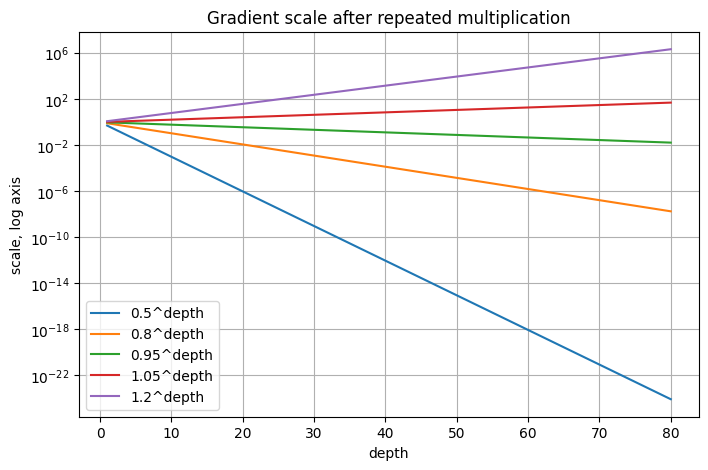

In [14]:
depth = np.arange(1, 81)
for factor in [0.5, 0.8, 0.95, 1.05, 1.2]:
    plt.semilogy(depth, factor**depth, label=f'{factor}^depth')
plt.title('Gradient scale after repeated multiplication')
plt.xlabel('depth'); plt.ylabel('scale, log axis'); plt.legend();


## Deep Dive E: Gradient Clipping Intuition

Gradient clipping limits a gradient when it becomes too large. It does not make the model smarter; it prevents one update from destroying training.

If the gradient norm is larger than a chosen threshold, the gradient vector is scaled down while keeping its direction.


original gradient: [30. 40.] norm: 50.0
clipped gradient: [3. 4.] norm: 5.0


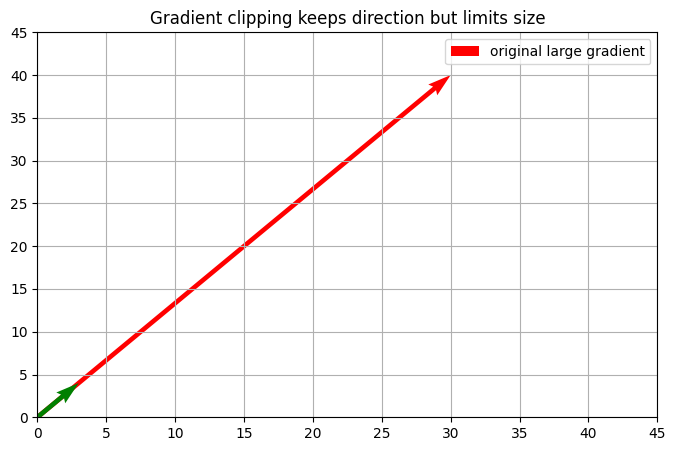

In [15]:
g = np.array([30.0, 40.0])
norm = np.linalg.norm(g)
threshold = 5.0
g_clipped = g * min(1, threshold / norm)
print('original gradient:', g, 'norm:', norm)
print('clipped gradient:', g_clipped, 'norm:', np.linalg.norm(g_clipped))
plt.quiver([0,0],[0,0],[g[0],g_clipped[0]],[g[1],g_clipped[1]], angles='xy', scale_units='xy', scale=1, color=['red','green'])
plt.xlim(0,45); plt.ylim(0,45)
plt.title('Gradient clipping keeps direction but limits size')
plt.legend(['original large gradient','clipped gradient']);


## Missing Concept Expansion: More Backpropagation and Autodiff Concepts

This section fills deeper concepts that are important after the basic chain rule is clear.


### Reverse-Mode vs Forward-Mode Automatic Differentiation

There are two major automatic differentiation modes:

* **Forward-mode AD:** efficient when there are few inputs and many outputs.
* **Reverse-mode AD:** efficient when there are many inputs and one scalar loss.

Deep learning usually uses reverse-mode AD because neural networks have millions of parameters but training normally optimizes one scalar loss.


### Vector-Jacobian Product (VJP)

Backpropagation usually does not build the full Jacobian matrix. Instead, it computes vector-Jacobian products.

This is efficient because the model may have millions of parameters. Building a full Jacobian would be too expensive.

**Plain meaning:** backpropagation asks, “given the gradient from later layers, what gradient should be sent backward through this operation?”


### Jacobian-Vector Product (JVP)

JVP is more connected to forward-mode AD. It asks how outputs change when inputs move in a chosen direction.

**Where it is used:** some sensitivity analysis, higher-order optimization, and advanced autodiff systems.

**Difference from VJP:** VJP moves gradient information backward; JVP pushes directional derivative information forward.


### Topological Order

Backpropagation must process graph operations in reverse dependency order. You cannot compute a node's gradient until gradients from all later nodes that depend on it are known.

This ordering is called topological order.

**Common mistake in manual backprop:** calculating one branch gradient and forgetting another branch that also depends on the same value.


### Broadcasting Gradients and Unbroadcasting

Broadcasting in the forward pass can hide shape changes. During backward pass, gradients must be reduced back to the original shape.

Example: if bias `b` with shape `(features,)` is added to a batch output with shape `(batch, features)`, then the gradient for `b` must sum over the batch axis.


In [16]:
batch, features = 4, 3
dZ = rng.normal(size=(batch, features))
db = dZ.sum(axis=0)
print('dZ shape:', dZ.shape)
print('bias gradient shape after unbroadcasting:', db.shape)
print('bias gradient:', db)


dZ shape: (4, 3)
bias gradient shape after unbroadcasting: (3,)
bias gradient: [-0.81810078 -1.89328195 -0.7245386 ]


### Subgradient at Non-Smooth Points

Some functions are not differentiable at certain points. ReLU is not differentiable at exactly 0.

Frameworks choose a practical subgradient, often 0 at ReLU(0). This works in practice because exact zero inputs are not usually the main issue.

**Common mistake:** thinking ReLU is invalid because it is not differentiable at one point. It is still very useful for gradient-based learning.


### Gradient Accumulation Over Mini-Batches

Some frameworks accumulate gradients until they are cleared. This is useful when simulating a larger batch across several smaller batches, but it can cause bugs if accidental.

Correct training loop pattern:

1. clear old gradients;
2. forward pass;
3. compute loss;
4. backward pass;
5. optimizer step.

If gradients are not cleared, the next update may include old gradient information.


### Stop Gradient / Detach

Stop-gradient means intentionally preventing gradients from flowing through a value.

**Where it is used:**

* freezing a pretrained feature extractor;
* target networks in reinforcement learning;
* contrastive/self-supervised methods;
* logging values without tracking gradients.

**Common mistake:** detaching a tensor accidentally and then wondering why earlier layers do not learn.


### Higher-Order Gradients

A first-order gradient is the derivative of loss with respect to parameters. A higher-order gradient differentiates a gradient again.

**Where it is used:** meta-learning, some optimization research, physics-informed networks, and curvature analysis.

**Why it is expensive:** it requires keeping more graph information in memory.


### Gradient Checkpointing

Backpropagation needs forward activations. Storing all activations can use a lot of memory in deep networks.

Gradient checkpointing saves memory by storing only some activations and recomputing others during the backward pass.

**Tradeoff:** lower memory use, more computation time.


### In-Place Operation Problems

An in-place operation changes a value directly. This can break autograd if the old value is needed for backward calculation.

**Example idea:** if sigmoid output is overwritten before backward pass, the sigmoid derivative may not be computable correctly.

**Safe habit:** avoid in-place changes on tensors needed for gradients unless you know the framework supports that specific operation.


### Numerical Gradient Checking Limits

Gradient checking is useful, but not perfect.

It can fail or mislead when:

* the function has randomness;
* dropout/batchnorm are in training mode;
* epsilon is poorly chosen;
* the function is not smooth at the checked point;
* floating-point precision is low;
* the model is large and checking every parameter is too slow.

Use it mainly for small custom layers or custom loss functions.


## Step 11: Backpropagation Mistakes

* **Missing cache:** backward formulas often need forward values.
* **Wrong shape:** $dW$, $db$, and $dX$ must match the values they correspond to.
* **No batch average:** gradient scale changes when batch size changes.
* **Updating too early:** calculate all gradients before changing parameters.
* **Not clearing gradients:** some frameworks accumulate gradients by default.
* **Detached graph:** gradients stop flowing if tensors are detached accidentally.

## Module 05 Summary

Backpropagation is chain rule through a computational graph. Local gradients describe one operation; upstream gradients bring information from later operations; downstream gradients carry information backward. Autograd automates this process, but the learner still needs to understand graph flow, shapes, losses, and gradient behavior.
